# Building an MLP Classifier

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

In [3]:
from sklearn.datasets import make_moons

In [6]:
# Generate dataset
X, y = make_moons(
    n_samples=1000,
    noise=0.2,
    random_state=42
)

In [7]:
# Convert Numpy arrays into PyTorch tensors
X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.long)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: torch.Size([1000, 2])
y shape: torch.Size([1000])


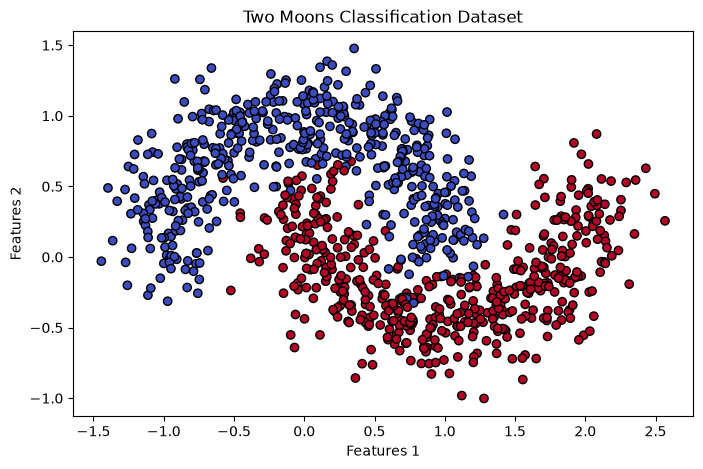

In [9]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    cmap="coolwarm",
    edgecolors="k"
)

plt.xlabel("Features 1")
plt.ylabel("Features 2")
plt.title("Two Moons Classification Dataset")
plt.show()

In [10]:
# Split the dataset into training and testing sets
# Training set (80%): Used to learn model parameters.
# Testing set (20%): Used to evaluate how well the
# model generalizes to unseen data.
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X.numpy(),
    y.numpy(),
    test_size=0.2,
    random_state=42,
    stratify=y.numpy()
)

# Convert Numpy arrays into PyTorch tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

print("Training features:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing features:", X_test.shape)
print("Testing labels:", y_test.shape)

Training features: torch.Size([800, 2])
Training labels: torch.Size([800])
Testing features: torch.Size([200, 2])
Testing labels: torch.Size([200])


In [11]:
# Define the model architecture
model = nn.Sequential(
    nn.Linear(2, 16),
    nn.ReLU(),
    nn.Linear(16, 16),
    nn.ReLU(),
    nn.Linear(16, 2)
)

sample = X_train[:5]
output = model(sample)

print(output)
print(output.shape)

tensor([[-0.1297, -0.1644],
        [-0.0230,  0.0641],
        [ 0.1247,  0.0281],
        [-0.2305, -0.1251],
        [ 0.0445, -0.0200]], grad_fn=<AddmmBackward0>)
torch.Size([5, 2])


In [12]:
# Loss function and optimizer
loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

In [13]:
# Training loop
num_epochs = 100
train_losses = []

In [14]:
for epoch in range(num_epochs):
    # clear the gradients
    optimizer.zero_grad()

    # forward pass
    logits = model(X_train)

    # compute the loss
    loss = loss_fn(logits, y_train)

    # backward pass
    loss.backward()

    # update the parameters
    optimizer.step()

    train_losses.append(loss.item())

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch + 1}, Loss: {loss.item():.4f}")


Epoch 10, Loss: 0.5566
Epoch 20, Loss: 0.3419
Epoch 30, Loss: 0.2976
Epoch 40, Loss: 0.2635
Epoch 50, Loss: 0.2389
Epoch 60, Loss: 0.2095
Epoch 70, Loss: 0.1714
Epoch 80, Loss: 0.1298
Epoch 90, Loss: 0.0988
Epoch 100, Loss: 0.0825


In [15]:
# Evaluate the model on the test set
model.eval()  # Set the model to evaluation mode

# disable gradient tracking
with torch.no_grad():

    # training predictions
    train_logits = model(X_train)
    train_predictions = torch.argmax(train_logits, dim=1) # picks higher-scoring class per row

    # testing predictions
    test_logits = model(X_test)
    test_predictions = torch.argmax(test_logits, dim=1) # picks higher-scoring class per row

    # calculate accuracy
    train_accuracy = (train_predictions == y_train).float().mean()
    test_accuracy = (test_predictions == y_test).float().mean()

print(f"Training accuracy: {train_accuracy.item() * 100:.2f}%")
print(f"Testing accuracy: {test_accuracy.item() * 100:.2f}%")

Training accuracy: 96.88%
Testing accuracy: 99.00%


### Observation

- Train 96.88%: this is exactly 775 of 800, which fits a 1,000-sample dataset with an 80/20 split. If your split differs, the arithmetic changes but the reading doesn't.
- Test 99.00%: on a 200-sample test set, this is 198 of 200 correct, so the model got only 2 test points wrong.

**Why test is higher than train**

1. A small test set. Each test sample is worth 0.5 percentage points. The difference between 96.88% and 99% is about 4 samples' worth. Re-splitting with a different random_state could easily flip the ordering.
2. Luck in the split. With noise=0.2, a few points from the two moons overlap, and they're essentially impossible to classify correctly. If more of those landed in the training set, training accuracy is capped lower.
3. The model is still training. The loss was still falling at epoch 100, so the model hasn't fully fit the training data yet.

In [16]:
import numpy as np

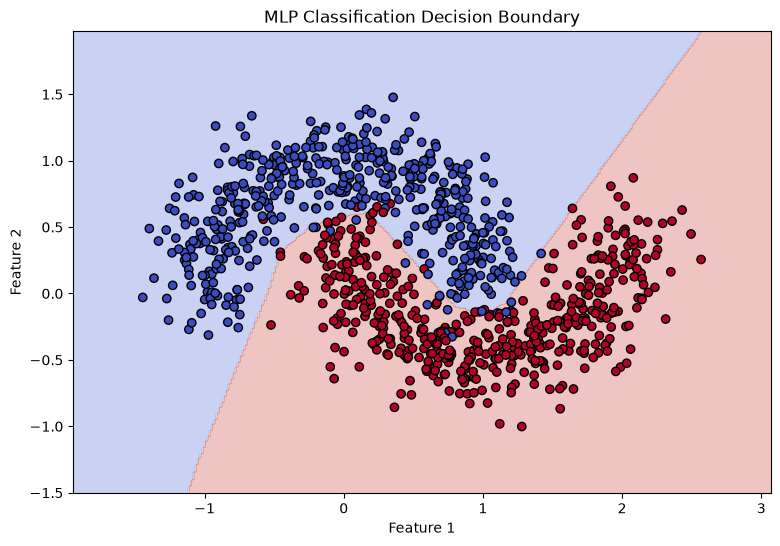

In [18]:
# Evaluation mode
model.eval()

# create coordinate ranges
x_min, x_max = X[:, 0].min().item() - 0.5, X[:, 0].max().item() + 0.5
y_min, y_max = X[:, 1].min().item() - 0.5, X[:, 1].max().item() + 0.5

# generate a grid of points
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

# convert grid coordinates to a PyTorch tensor
grid = torch.tensor(
    np.c_[xx.ravel(), yy.ravel()],
    dtype=torch.float32
)

# predict the class for each point in the grid
with torch.no_grad():
    logits = model(grid)
    predictions = torch.argmax(logits, dim=1)

# reshape predictions to match the grid
Z = predictions.numpy().reshape(xx.shape)

# plot decision boundary and original samples
plt.figure(figsize=(9, 6))

plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    cmap="coolwarm",
    edgecolors="k"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("MLP Classification Decision Boundary")
plt.show()

The MLP learned a non-linear, piecewise-linear decision boundary that separates the two interleaving moons. Misclassifications occur only in the overlap region caused by the dataset's noise.

- The boundary is curved, not a straight line. The red region wraps up between the two moons, with a peak near (0.3, 0.35), and the blue region sweeps over the top moon and down toward (1, 0). A linear model can't draw this. It's what the ReLU layers add.
- The boundary is piecewise linear. Look closely and it's made of straight segments joined at corners, for example the diagonal edge on the right running from about (1, 0) up to (2.2, 1.9), and the sharp corner near the peak. This is expected. A ReLU network computes a function made of linear pieces, and 16 hidden units per layer give enough pieces to approximate the curve. A tanh network or a larger one would give a smoother boundary.
- The few errors sit where the moons overlap. A handful of red points near (0.3 to 0.6, 0.3 to 0.6) fall in the blue zone, and a few blue points reach into red near the tip of the top moon around (1, 0). With noise=0.2 these points sit inside the other class's territory, so no boundary could classify them correctly. They explain why we get about 97–99% and not 100%.